<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/Phase5_LLMs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 5 — LLMs: adding world knowledge
**Tag Recommender Agent roadmap · Weeks 8–10**

### 🎯 The idea in one sentence
Ask a **Large Language Model** to read the product and **choose its tags** — because an LLM knows things that are **not in our dataset**: *"a body butter is moisturizing"*, *"a bonnet is not a cream"*, *"Aqua Bounce is a gel"*.

### Why this phase, after Phases 2–4?
Three phases tried three kinds of extra information — a deeper text model, similar products, relations between tags — and all hit the **same ceiling (P@3 ≈ 0.46)**. The reason: they are all **derived from the same vendor data** (short titles + incomplete tags).

An LLM is the first source of knowledge from **outside** this dataset: it was trained on a huge amount of text from the web. If world knowledge helps, we should see it on the **implicit tags** (not written in the title), where everything so far was stuck at ~64%.

### What is an LLM (in 4 lines)?
- A Transformer (like DistilBERT) trained to **predict the next word**, on trillions of words
- Then **instruction-tuned**: trained to follow instructions in a chat format (system / user / assistant)
- You talk to it with a **prompt**; it **generates** an answer word by word
- We use **Qwen2.5-1.5B-Instruct**: small (1.5 billion parameters) but runs on a free Colab T4 GPU

### Our design: the LLM **chooses from candidates**
An LLM left alone invents tags ("Hair Type: luscious") that are not in our 214-tag vocabulary. So:
1. **TF-IDF + LR** (Baseline 1) proposes the **top-15 candidate tags** for each product
2. The **LLM picks** the ones that really apply, answering in **JSON**
3. We check every answer against the vocabulary → invented tags are **counted and dropped**

*Forecasting analogy:* the statistical model gives a short list of plausible scenarios; an **expert forecaster** with world knowledge picks the right ones.

### What you will do
| Section | What | Roadmap task |
|---|---|---|
| 1–2 | Load data, candidates, **500-product evaluation sample** | — |
| 3 | Load the LLM, first prompt | 📘 Prompting |
| 4 | Structured **JSON** output + safe parsing | 📘 Structured JSON output |
| 5 | **Zero-shot** tagging | 📘 zero-shot |
| 6 | **Few-shot** (3 worked examples in the prompt) | 📘 few-shot |
| 7 | **RAG**: similar products in the prompt | 🔨 RAG tagger |
| 8 | **Abstention**: "if not sure, leave it out" | 🔨 Abstention (NONE) |
| 9 | **LoRA fine-tuning** on our own tags | 🎯 LoRA fine-tune |
| 10 | Scoreboard · 11 Error analysis · 12 Save · 13 Summary | 📊 Evaluate vs baselines |

> **Runtime:** `Runtime → Change runtime type → T4 GPU` (required). Each LLM run on 500 products takes ~3–8 min; LoRA training ~10–20 min.

## 0 · Setup

In [2]:
!pip -q install -U transformers accelerate peft

In [3]:
import json, re, os, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)
np.random.seed(42)
BLUE, GRAY, ORANGE, GREEN, PURPLE, INK = "#2a6fdb", "#9aa0a6", "#e8710a", "#1e8e3e", "#9334e6", "#222222"

## 1 · Load data, rebuild Baseline 1, load neighbours
**Why:** the LLM needs three ingredients from earlier phases:
- **Products, tags, split** (Phase 2) → what to tag and how to score it
- **TF-IDF + LR scores** (Baseline 1, rebuilt ~1 min) → the **candidate list** for each product
- **Nearest neighbours** (Phase 3) → the **similar products** shown in the RAG prompt (Section 7)

In [4]:
from google.colab import drive
drive.mount("/content/drive")
DIR = "/content/drive/MyDrive/tag_agent"

Mounted at /content/drive


In [5]:
CATEGORY = "All_Beauty"
P2, P3, P4, OUT = f"{DIR}/phase2", f"{DIR}/phase3", f"{DIR}/phase4", f"{DIR}/phase5"
os.makedirs(OUT, exist_ok=True)

data = pd.read_pickle(f"{P2}/{CATEGORY}_phase2.pkl")
Y    = np.load(f"{P2}/Y.npy")
TAGS = np.array(json.load(open(f"{P2}/tags.json")))
m_tr, m_va, m_te = [(data["split"] == s).values for s in ("train", "val", "test")]
Y_tr, Y_va, Y_te = Y[m_tr], Y[m_va], Y[m_te]
texts = data["clean"].values
tr_df, te_df = data[m_tr].reset_index(drop=True), data[m_te].reset_index(drop=True)

NICE = np.array([t.replace("=", ": ") for t in TAGS])          # "Hair Type: wavy" — how the LLM sees tags
NICE2IDX = {n.lower(): i for i, n in enumerate(NICE)}
neigh_te = np.load(f"{P3}/neighbours_test.npz")["idx"]          # test → nearest train products (MiniLM)
COND = np.load(f"{P4}/tag_graph_matrices.npz")["COND"]          # P(b | a) from the tag graph
print(f"Products: {len(data):,} | tags: {len(TAGS)} | test: {m_te.sum():,}")

Products: 19,401 | tags: 211 | test: 2,983


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score

t0 = time.time()
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.5, max_features=100_000, sublinear_tf=True)
X_tr = tfidf.fit_transform(texts[m_tr])
lr = OneVsRestClassifier(LogisticRegression(C=4.0, solver="liblinear", max_iter=1000), n_jobs=-1).fit(X_tr, Y_tr)
S_va_lr = lr.predict_proba(tfidf.transform(texts[m_va]))
S_te_lr = lr.predict_proba(tfidf.transform(texts[m_te]))

def binarize(S, thr):
    P = (S >= thr).astype(int); empty = P.sum(1) == 0
    P[empty, S[empty].argmax(1)] = 1
    return P
grid = np.round(np.arange(0.05, 0.95, 0.05), 2)
thr_lr = float(grid[np.argmax([f1_score(Y_va, binarize(S_va_lr, g), average="micro", zero_division=0) for g in grid])])
print(f"Baseline 1 rebuilt in {time.time() - t0:.0f}s | threshold {thr_lr}")

Baseline 1 rebuilt in 67s | threshold 0.2


## 2 · Evaluation sample, candidates and metrics
### Why a 500-product sample?
An LLM **generates text** for every product → ~100× slower than LR. Running every variant on all ~2,900 test products would take hours. So we evaluate on a **fixed random sample of 500 test products** — and, to stay fair, **the baselines are re-scored on the same 500**.

### Candidates: the LLM chooses from a short list
For each product, the **top-15 tags from TF-IDF + LR** become the candidate list.
⚠️ This sets a **ceiling**: if a true tag is not among the 15 candidates, the LLM cannot pick it. We measure this ceiling below ("candidate recall").

### Metrics for a *set* of tags
An LLM returns a **set** of tags (no scores). So we use set-based metrics (same as in Phase 2's threshold route):
- **Precision** = of the tags it chose, how many are right?
- **Recall** = of the true tags, how many did it choose?
- **F1** = balance of the two (micro, over all products)
- **avg tags** = how many tags per product it chose · **invalid** = tags not in the vocabulary (hallucinations)

For **P@3** we still need a ranking: chosen tags go first (ordered by LR score), then the rest by LR score.

In [14]:
N_EVAL, N_CAND = 30, 15
rng = np.random.default_rng(0)
EVAL = np.sort(rng.choice(len(te_df), N_EVAL, replace=False))       # row numbers inside the test set
Y_ev, S_ev_lr = Y_te[EVAL], S_te_lr[EVAL]
CAND = np.argsort(-S_ev_lr, axis=1)[:, :N_CAND]                     # candidate tag indices per product

cand_recall = np.mean([Y_ev[i, CAND[i]].sum() / Y_ev[i].sum() for i in range(N_EVAL)])
print(f"Evaluation sample: {N_EVAL} test products")
print(f"Candidate recall (true tags inside the top-{N_CAND}): {cand_recall:.3f}  ← the LLM's ceiling")

Evaluation sample: 30 test products
Candidate recall (true tags inside the top-15): 0.900  ← the LLM's ceiling


In [15]:
def set_metrics(Yt, Pset):
    tp = (Yt & Pset).sum(); fp = ((1 - Yt) & Pset).sum(); fn = (Yt & (1 - Pset)).sum()
    p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
    return {"precision": p, "recall": r, "F1": 2 * p * r / max(p + r, 1e-9),
            "avg tags": Pset.sum(1).mean(), "empty %": 100 * (Pset.sum(1) == 0).mean()}

def p_at_3(Yt, S):
    top = np.argsort(-S, axis=1)[:, :3]
    return np.take_along_axis(Yt, top, 1).sum(1).mean() / 3

board = {}
def add_row(name, Pset, S_rank, invalid=0.0, sec=None):
    board[name] = {**set_metrics(Y_ev, Pset), "P@3": p_at_3(Y_ev, S_rank),
                   "invalid / product": invalid, "sec / product": sec}
    return pd.DataFrame(board).T.round(3)

add_row("TF-IDF + LR (threshold)", binarize(S_ev_lr, thr_lr), S_ev_lr)
oracle = np.array([np.isin(np.arange(len(TAGS)), CAND[i]) & (Y_ev[i] == 1) for i in range(N_EVAL)]).astype(int)
add_row("Candidate ceiling (oracle)", oracle, S_ev_lr + oracle)

,precision,recall,F1,avg tags,empty %,P@3,invalid / product,sec / product
TF-IDF + LR (threshold),0.657,0.575,0.613,2.333,0.0,0.544,0.0,NaN
Candidate ceiling (oracle),1.000,0.888,0.940,2.367,0.0,0.744,0.0,NaN


 📊 Reference rows: where we start and the best possible
**Goal:** before any LLM runs, set two references for the same 500 products.

**Row 1: TF-IDF + LR (threshold)**, where we start: precision **0.574** · recall **0.578** · F1 **0.576** · avg tags 2.34 · P@3 **0.473** (≈ 0.463 on the full test set → the sample is representative). *invalid / sec* don't apply to LR.

**Row 2: Candidate ceiling (oracle)**, the best possible: a **perfect chooser** that picks exactly the true tags among the 15 candidates.
*Example:* true = {human hair, wavy, natural}; candidates contain human hair and wavy but **not** natural → picks {human hair, wavy}: 2 right, 0 wrong, 1 missed.
- **precision 1.000** (never wrong, by definition)
- **recall 0.899** → **10% of true tags are not among the 15 candidates**: the ceiling no LLM can beat
- **F1 0.947** = best possible · **avg tags 2.08** · **empty 3.2%** (16 products with no true tag among the candidates) · **P@3 0.652** = best possible (products have only 2–3 tags)

**Together:** the candidate list is good (90% of true tags inside), and there is **a lot of room** between LR (F1 0.576) and the ceiling (0.947) → the question for the LLM is **how well it chooses**.

## 3 · Load the LLM and send a first prompt 📘
**How you talk to a chat LLM:** a list of **messages**, each with a role:
- **system** → who the model is and how it should behave ("You are an e-commerce catalogue assistant")
- **user** → the actual task (the product + the instructions)
- the model replies as **assistant**

The **chat template** turns these messages into the exact text format the model was trained on.

**Decoding settings:** `do_sample=False` (**greedy**: always the most likely next word) → the same prompt always gives the same answer, which we need for fair comparisons. `max_new_tokens` limits the answer length.

**Batching:** we send 16 prompts at once (like a DataLoader). `padding_side="left"` lines up the prompts at the right edge, so generation starts at the same position for all.

In [17]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
llm = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float32, device_map="cpu")



tok = AutoTokenizer.from_pretrained(MODEL_ID, padding_side="left")
llm.eval()
print(f"{MODEL_ID}: {sum(p.numel() for p in llm.parameters()) / 1e9:.2f}B parameters")

@torch.no_grad()
def generate(prompts, max_new_tokens=96, batch_size=16, model=None):
    model = model or llm
    outs = []
    for s in range(0, len(prompts), batch_size):
        chat = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in prompts[s:s + batch_size]]
        enc = tok(chat, return_tensors="pt", padding=True).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.eos_token_id)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

hello = [[{"role": "system", "content": "You are a helpful e-commerce catalogue assistant."},
          {"role": "user", "content": "In one sentence: what is a 'body butter' and is it usually moisturizing?"}]]
print(generate(hello, max_new_tokens=60)[0])

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Qwen/Qwen2.5-0.5B-Instruct: 0.49B parameters
A body butter is a cream applied to the skin for hydration, often used as an exfoliant or barrier against environmental factors.


**What to look for:** a sensible one-sentence answer → the model has **world knowledge** about beauty products that none of our earlier models had.

### ❓ Does the LLM use our data or its own knowledge? Both, on purpose
**We *want* its own knowledge:** that's the point of Phase 5. Phases 2–4 used only our data and hit a ceiling (P@3 ≈ 0.46).
*Example:* "A body butter is a moisturizing, nourishing cream…": nothing in our dataset told it that → **world knowledge** that could find **implicit tags**.

**But we control the answer (3 guardrails):**
| Guardrail | Prevents |
|---|---|
| **Candidate list** (top-15 from TF-IDF + LR) | tags outside **our vocabulary** |
| **JSON parser** | anything not in the candidates → **counted invalid and dropped** |
| **Strict prompt** (Section 8) | tags without support in the text or similar products |

→ Its **knowledge** decides *which* candidates fit; **our data** decides *what* the possible answers are.

**We don't trust it, we measure it:** answers are compared with the true tags → knowledge helps if precision/recall rise (esp. **implicit** tags, Section 11); hallucination shows as lower precision / higher **invalid**.
We can't see **why** it picked a tag → the Phase 6 **verifier** asks for **evidence**.

⚠️ **Data contamination:** the LLM may have seen Amazon pages during training and "remember" products → test on another dataset (AE-110K / MAVE) in Phase 7.

## 4 · Structured JSON output + safe parsing 📘
**The problem:** the LLM answers with **text**, but to compute precision/recall we need a clean list of **tags**, automatically, for 500 products.

**Step 1: ask for a fixed format (JSON).**
A free answer like *"I think it's probably a wavy wig made of human hair, maybe natural too…"* can't be read automatically. So the prompt says: **answer only in this format**:
```json
{"tags": ["Hair Type: wavy", "Material: human hair"]}
```
JSON = a **box** `{ }` with a **label** `"tags"` and a **list** `[ ]` → readable by humans and computers.

**Step 2: LLMs don't always obey → the parser is defensive.** Three typical answers:

| Answer | What the parser does | Result |
|---|---|---|
| **A, perfect:** `{"tags": ["Hair Type: wavy", "Material: human hair"]}` | reads the list; both are candidates | chosen: wavy, human hair · invalid 0 |
| **B, chatty + invented:** `Sure! {"tags": ["Hair Type: wavy", "Hair Type: luscious"]} Hope it helps.` | skips text before `{`; "luscious" is **not** a candidate | chosen: wavy · **invalid 1** |
| **C, cut off:** `{"tags": ["Hair Type: wavy", "Material: hum` | JSON broken → **fallback:** take every complete quoted text | chosen: wavy · invalid 0 |

**Step 3: final rule:** only tags from the **15 candidates** are kept; everything else is dropped and counted in **"invalid / product"** = our **hallucination meter**.

In [18]:
def parse_tags(answer, cand_idx):
    allowed = {NICE[j].lower(): j for j in cand_idx}
    start = answer.find("{")
    block = answer[start:] if start >= 0 else answer          # from the first "{" (ignore text before it)
    end = block.rfind("}")
    items = []
    try:
        items = json.loads(block[:end + 1]).get("tags", []) if end >= 0 else []
    except Exception:
        items = []
    if not items:                                               # broken / cut-off JSON → take quoted strings
        items = re.findall(r'"([^"]+)"', block)
    items = [str(x).strip().lower() for x in items if isinstance(x, (str, int, float))]
    items = [x for x in items if x != "tags"]
    chosen = sorted({allowed[x] for x in items if x in allowed})
    invalid = sum(x not in allowed for x in items)
    return chosen, invalid

# check the parser on three typical answers
cands = CAND[0]
good  = '{"tags": ["' + NICE[cands[0]] + '", "' + NICE[cands[1]] + '"]}'
messy = 'Sure! Here you go:\n{"tags": ["' + NICE[cands[0]] + '", "Hair Type: luscious"]}\nHope it helps.'
broken = '{"tags": ["' + NICE[cands[1]] + '", '
for name, ans in [("clean JSON", good), ("text around + invented tag", messy), ("broken JSON", broken)]:
    print(f"{name:28s} → chosen {[str(NICE[j]) for j in parse_tags(ans, cands)[0]]}, invalid {parse_tags(ans, cands)[1]}")

clean JSON                   → chosen ['Item Form: gel', 'Skin Type: sensitive'], invalid 0
text around + invented tag   → chosen ['Item Form: gel'], invalid 1
broken JSON                  → chosen ['Skin Type: sensitive'], invalid 0


**Check:** the clean answer gives 2 tags; the messy one keeps the valid tag and counts *"Hair Type: luscious"* as **1 invalid**; the broken JSON still recovers its tag via the fallback.

## 5 · Zero-shot tagging 📘
**Zero-shot** = the model gets **only instructions**, no examples. It must rely on what it already knows.

**The prompt** (one per product):
- **system:** who it is
- **user:** the product text (first 600 characters) + the 15 candidate tags + the rules: *choose all that apply · copy them exactly · answer with JSON only*

The function `run_variant` does the full loop for any prompt style: build prompts → generate → parse → score → add a scoreboard row.

💡 In Sections 5–8 only the **prompt** changes, so where are "vectorize → search → vote"?
| Step | Phases 2–4 (we built each step) | Phase 5 (LLM) |
|---|---|---|
| **Represent** text → numbers | TF-IDF / MiniLM | **inside** the LLM (tokenizer + Transformer layers) |
| **Find evidence** | FAISS / kNN | none, or **pasted** into the prompt (RAG, Section 7) |
| **Decide** which tags | LR / kNN voting / graph rule | the LLM **generates** its answer |
| **Training** | LR / DistilBERT on our data | **none** (weights frozen); LoRA in Section 9 |

**In-context learning:** the model learns **from the prompt itself**, at answer time, without training.
Each section changes **one thing** in the prompt (instructions → + examples → + similar products → + "be strict") and measures the effect.

**What this cell builds:** 3 solved **train** examples from different product families; each shows the **true tags + plausible distractors** (graph partners, Phase 4) as candidates and the **correct JSON** answer → the model sees how to **choose**, how many tags, and the exact format.
*Analogy:* handing a forecaster three past cases with the correct forecast before asking about today.

In [19]:
SYSTEM = "You are an expert e-commerce catalogue assistant. You assign attribute tags to beauty products."

def product_block(i):
    return f'Product text:\n{te_df.loc[EVAL[i], "clean"][:600]}'

def cand_block(i):
    return "Candidate tags (Attribute: value):\n" + "\n".join(f"- {NICE[j]}" for j in CAND[i])

RULES = ('Choose ALL candidate tags that apply to this product. Use only tags from the candidate list, copied exactly.\n'
         'Answer with JSON only, in this format: {"tags": ["Attribute: value", ...]}')

def zero_shot_prompt(i):
    return [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"{product_block(i)}\n\n{cand_block(i)}\n\n{RULES}"}]

def run_variant(name, make_prompt, model=None):
    prompts = [make_prompt(i) for i in range(N_EVAL)]
    t0 = time.time(); answers = generate(prompts, model=model); sec = (time.time() - t0) / N_EVAL
    Pset = np.zeros_like(Y_ev); invalid = []
    for i, a in enumerate(answers):
        chosen, bad = parse_tags(a, CAND[i]); Pset[i, chosen] = 1; invalid.append(bad)
    S_rank = S_ev_lr + Pset                                  # chosen tags first, then by LR score
    preds[name] = {"answers": answers, "Pset": Pset}
    return add_row(name, Pset, S_rank, invalid=float(np.mean(invalid)), sec=sec)

preds = {}
print(zero_shot_prompt(0)[1]["content"][:900])

Product text:
avena New 328429 Bath & Shower Gel 25.5Z Instituto Espanol -Pack Bath Products Wholesale Bulk Health & Beauty Bath Products Gel.

Candidate tags (Attribute: value):
- Item Form: gel
- Skin Type: sensitive
- Skin Type: dry
- Material Feature: cruelty free
- Material Feature: vegan
- Finish Type: glossy
- Item Form: cream
- Finish Type: matte
- Color: green
- Color: black
- Scent: coconut
- Color: blue
- Item Form: foam
- Skin Type: oily
- Product Benefits: moisturizing

Choose ALL candidate tags that apply to this product. Use only tags from the candidate list, copied exactly.
Answer with JSON only, in this format: {"tags": ["Attribute: value", ...]}


In [20]:
run_variant("LLM zero-shot", zero_shot_prompt)

,precision,recall,F1,avg tags,empty %,P@3,invalid / product,sec / product
TF-IDF + LR (threshold),0.657,0.575,0.613,2.333,0.0,0.544,0.000,NaN
Candidate ceiling (oracle),1.000,0.888,0.940,2.367,0.0,0.744,0.000,NaN
LLM zero-shot,0.177,0.788,0.290,11.833,0.0,0.500,0.233,10.849


### Result: LLM zero-shot (Qwen2.5-0.5B, CPU, 30 test products)

**Goal:** give the LLM the product text + 15 candidate tags and check whether it can **pick only the correct ones**. We compare it with TF-IDF + LR on the same 30 products.

**What happened:** the model **barely chose**. It kept almost the whole list.

| | precision | recall | F1 | avg tags | P@3 |
|---|---|---|---|---|---|
| TF-IDF + LR | 0.657 | 0.575 | **0.613** | 2.3 | 0.544 |
| Oracle (ceiling) | 1.000 | 0.888 | 0.940 | 2.4 | 0.744 |
| LLM zero-shot | 0.177 | 0.788 | **0.290** | **11.8** | 0.500 |

**How to read the LLM row:**
- **avg tags 11.8 vs. truth ≈ 2.4:** it returned ~12 of the 15 candidates.
- **recall 0.788 (high):** keeping almost everything catches most true tags. This is easy and doesn't mean the model is good.
- **precision 0.177 (very low):** only ~2 of its ~12 tags are correct.
- **F1 0.290:** half of LR's 0.613, because of the low precision.
- **P@3 0.500 ≈ LR's 0.544:** the candidates are listed in LR's ranking order and the model copied that order. So this is mostly LR's ranking, not the LLM's understanding.
- **invalid 0.23 / product:** about 1 in 4 products got a tag that is not in the list. The parser removes these.
- **10.8 s / product** on CPU.

**Why:** a 0.5B model is too small to follow *"choose only the correct ones"*, so it copies the list. This is a known small-model behaviour, not a code bug.

**Next:** few-shot (examples where only *some* candidates are correct) and strict (stay silent when unsure) target exactly this problem. Watch whether **avg tags drops** and **precision rises**.

*Note: 30 products on CPU with a 0.5B model is a learning run. Final thesis numbers: 1.5B on GPU, 500 products.*

## 6 · Few-shot: show 3 worked examples 📘
**Few-shot** = put a few **solved examples** in the prompt before the real product. The model copies the **format** and the **level of detail** (how many tags, how literal).

We pick 3 **train** products from different product families (they must come from train — showing test products would leak labels). Each example has its true tags plus realistic distractors as candidates, and the correct JSON answer.

*Analogy:* giving a new colleague three filled-in forms before asking them to fill in the next one.

In [21]:
def distractor_candidates(true_idx, n=N_CAND, seed=0):
    # true tags + "hard" distractors from the same product family (graph partners), shuffled
    r = np.random.default_rng(seed)
    w = COND[true_idx].sum(0).astype(float) + 1e-6       # family partners weigh most; every tag possible
    w[true_idx] = 0                                        # never pick a true tag as a distractor
    extra = r.choice(len(TAGS), size=min(n - len(true_idx), (w > 0).sum()), replace=False, p=w / w.sum())
    cand = np.array(list(true_idx) + list(extra)); r.shuffle(cand)
    return cand

def pick_examples(k=3, seed=1):
    r = np.random.default_rng(seed); attrs_seen, out = set(), []
    for i in r.permutation(len(tr_df)):
        tags = tr_df.loc[i, "tags"]; first_attr = tags[0].split("=")[0]
        if 2 <= len(tags) <= 4 and first_attr not in attrs_seen and len(tr_df.loc[i, "clean"]) < 300:
            attrs_seen.add(first_attr); out.append(i)
        if len(out) == k: break
    return out

def example_block(i, seed):
    true_idx = [int(np.flatnonzero(TAGS == t)[0]) for t in tr_df.loc[i, "tags"] if t in set(TAGS)]
    cand = distractor_candidates(true_idx, seed=seed)
    user = (f'Product text:\n{tr_df.loc[i, "clean"][:300]}\n\nCandidate tags (Attribute: value):\n'
            + "\n".join(f"- {NICE[j]}" for j in cand) + f"\n\n{RULES}")
    answer = json.dumps({"tags": [NICE[j] for j in true_idx]})
    return [{"role": "user", "content": user}, {"role": "assistant", "content": answer}]

EXAMPLES = [m for k, i in enumerate(pick_examples()) for m in example_block(i, seed=k)]

def few_shot_prompt(i):
    return [{"role": "system", "content": SYSTEM}, *EXAMPLES,
            {"role": "user", "content": f"{product_block(i)}\n\n{cand_block(i)}\n\n{RULES}"}]

print("Example answer shown to the model:", EXAMPLES[1]["content"])

Example answer shown to the model: {"tags": ["Item Form: wand", "Recommended Uses For Product: face makeup", "Skin Type: normal"]}


In [22]:
run_variant("LLM few-shot", few_shot_prompt)

,precision,recall,F1,avg tags,empty %,P@3,invalid / product,sec / product
TF-IDF + LR (threshold),0.657,0.575,0.613,2.333,0.0,0.544,0.000,NaN
Candidate ceiling (oracle),1.000,0.888,0.940,2.367,0.0,0.744,0.000,NaN
LLM zero-shot,0.177,0.788,0.290,11.833,0.0,0.500,0.233,10.849
LLM few-shot,0.145,0.250,0.183,4.600,0.0,0.189,0.300,29.851


## 7 · RAG: show similar products in the prompt 🔨
**RAG = Retrieval-Augmented Generation:** before asking the LLM, **retrieve** relevant information and put it **in the prompt**.

Here we retrieve the **5 most similar train products** (the MiniLM neighbours from Phase 3) and show their **titles and tags**:
> *Similar products from the catalogue and their tags:*
> *1. "Brazilian Body Wave Bundles 3 pcs…" → Material: human hair, Hair Type: wavy*

**Why this could beat Phase 3's kNN:** kNN let neighbours **vote blindly** (a bonnet tagged "cream" still got a vote). The LLM can **read** the neighbours and **judge** which ones really resemble the product — combining retrieval with world knowledge.

This is the **same retrieval step** as Phase 3, with a smarter **"decide"** step.

In [23]:
def rag_block(i, k=5):
    rows = []
    for r, j in enumerate(neigh_te[EVAL[i], :k], 1):
        tags = ", ".join(t.replace("=", ": ") for t in tr_df.loc[j, "tags"])
        rows.append(f'{r}. "{tr_df.loc[j, "title_txt"][:90]}" → {tags}')
    return "Similar products from the catalogue and their tags (may be imperfect):\n" + "\n".join(rows)

def rag_prompt(i):
    return [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"{product_block(i)}\n\n{rag_block(i)}\n\n{cand_block(i)}\n\n{RULES}"}]

print(rag_prompt(0)[1]["content"][:1400])

Product text:
avena New 328429 Bath & Shower Gel 25.5Z Instituto Espanol -Pack Bath Products Wholesale Bulk Health & Beauty Bath Products Gel.

Similar products from the catalogue and their tags (may be imperfect):
1. "4711 Wunderwasser Shower Gel 150 ml" → Item Form: gel
2. "Zoella Beauty Tutti Fruity Foam Sweet Foam Shower Gel 250ml" → Item Form: foam, Item Form: gel
3. "Avon Magical Hydrating Shower Gel - 6.7 fl. oz." → Item Form: gel, Skin Type: dry
4. "Nivea Powerfruit Shower Gel, 250ml (Pack Of 2)" → Item Form: gel
5. "Ylang Ylang & Ginger - Bath & Shower Gel 12 oz." → Item Form: gel, Skin Type: oily

Candidate tags (Attribute: value):
- Item Form: gel
- Skin Type: sensitive
- Skin Type: dry
- Material Feature: cruelty free
- Material Feature: vegan
- Finish Type: glossy
- Item Form: cream
- Finish Type: matte
- Color: green
- Color: black
- Scent: coconut
- Color: blue
- Item Form: foam
- Skin Type: oily
- Product Benefits: moisturizing

Choose ALL candidate tags that apply to t

In [24]:
run_variant("LLM + RAG", rag_prompt)

,precision,recall,F1,avg tags,empty %,P@3,invalid / product,sec / product
TF-IDF + LR (threshold),0.657,0.575,0.613,2.333,0.0,0.544,0.000,NaN
Candidate ceiling (oracle),1.000,0.888,0.940,2.367,0.0,0.744,0.000,NaN
LLM zero-shot,0.177,0.788,0.290,11.833,0.0,0.500,0.233,10.849
LLM few-shot,0.145,0.250,0.183,4.600,0.0,0.189,0.300,29.851
LLM + RAG,0.197,0.775,0.315,10.467,0.0,0.522,0.167,18.913


## 8 · Abstention: "if you're not sure, leave it out" 🔨
**Why:** from the literature (Gao et al.): *"Material = NONE is better than a wrong Material = plastic"*. In a real marketplace, a **wrong tag is worse than a missing tag** — it sends customers to the wrong products.

**The change:** same RAG prompt, plus a stricter rule:
> *Only include a tag if the product text or the similar products clearly support it. If you are not sure, leave it out. If no tag is clearly supported, answer {"tags": []}.*

**What we expect:** **precision ↑**, **recall ↓**, more **empty** answers. This is the **precision–coverage trade-off**: like a forecaster who issues a warning only when confident.

In [25]:
STRICT = ("Only include a tag if the product text or the similar products clearly support it. "
          "If you are not sure about a tag, leave it out. If no tag is clearly supported, answer {\"tags\": []}.")

def strict_prompt(i):
    return [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": f"{product_block(i)}\n\n{rag_block(i)}\n\n{cand_block(i)}\n\n{RULES}\n{STRICT}"}]

print(strict_prompt(0)[1]["content"][-400:])

- Product Benefits: moisturizing

Choose ALL candidate tags that apply to this product. Use only tags from the candidate list, copied exactly.
Answer with JSON only, in this format: {"tags": ["Attribute: value", ...]}
Only include a tag if the product text or the similar products clearly support it. If you are not sure about a tag, leave it out. If no tag is clearly supported, answer {"tags": []}.


In [26]:
run_variant("LLM + RAG (strict / abstain)", strict_prompt)

,precision,recall,F1,avg tags,empty %,P@3,invalid / product,sec / product
TF-IDF + LR (threshold),0.657,0.575,0.613,2.333,0.0,0.544,0.000,NaN
Candidate ceiling (oracle),1.000,0.888,0.940,2.367,0.0,0.744,0.000,NaN
LLM zero-shot,0.177,0.788,0.290,11.833,0.0,0.500,0.233,10.849
LLM few-shot,0.145,0.250,0.183,4.600,0.0,0.189,0.300,29.851
LLM + RAG,0.197,0.775,0.315,10.467,0.0,0.522,0.167,18.913
LLM + RAG (strict / abstain),0.265,0.675,0.380,6.800,0.0,0.522,0.333,19.166


**How to read Sections 5–8 together:** look at the **precision / recall / avg tags** columns across the four LLM rows. Each prompt change should move them in a predictable direction — that's how you learn what the model actually responds to.

## 9 · LoRA fine-tuning: teach the LLM *our* tagging style 🎯
**Why:** prompting only *tells* the model what to do. Our tags have their **own conventions** (e.g. vendors call most wigs `Material: human hair`, `natural` is used very often). **Fine-tuning** lets the model **learn** them from our training data.

**The problem:** full fine-tuning updates all 1.5 billion parameters → too much memory for a T4.

**LoRA (Low-Rank Adaptation):**
- **freeze** the original model completely
- next to some weight matrices (the attention projections), add **two tiny matrices A and B** (rank r = 16) → their product A·B is a small **correction** to the frozen weight
- train **only A and B** → about **0.5%** of the parameters

*Forecasting analogy:* keep a big pretrained model fixed and train a **small correction layer** on your local data.

**Training data:** 2,000 **train** products → prompt (text + candidates) → answer = the **true tags as JSON**. Candidates = true tags + "hard" distractors from the same product family (graph partners), so the model learns to **choose**, not just copy.

**Loss:** only on the **answer** tokens (the prompt tokens are masked with −100) — the model learns to *write the right answer*, not to repeat the question.

In [27]:
N_TRAIN_LORA, MAX_LEN = 2000, 512

def train_example(i, seed):
    true_idx = [int(np.flatnonzero(TAGS == t)[0]) for t in tr_df.loc[i, "tags"] if t in set(TAGS)]
    cand = distractor_candidates(true_idx, seed=seed)
    user = (f'Product text:\n{tr_df.loc[i, "clean"][:600]}\n\nCandidate tags (Attribute: value):\n'
            + "\n".join(f"- {NICE[j]}" for j in cand) + f"\n\n{RULES}")
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user}]
    return msgs, json.dumps({"tags": [NICE[j] for j in true_idx]})

lora_rows = np.random.default_rng(3).choice(len(tr_df), N_TRAIN_LORA, replace=False)
lora_data = [train_example(i, seed=k) for k, i in enumerate(lora_rows)]
print(f"{len(lora_data):,} training examples · example answer: {lora_data[0][1]}")

2,000 training examples · example answer: {"tags": ["Hair Type: curly", "Material: human hair", "Special Feature: glueless"]}


In [ ]:
from peft import LoraConfig, get_peft_model

def encode(msgs, answer):
    prompt = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    a_ids = tok(answer + tok.eos_token, add_special_tokens=False)["input_ids"]
    ids = (p_ids + a_ids)[:MAX_LEN]
    labels = ([-100] * len(p_ids) + a_ids)[:MAX_LEN]            # loss only on the answer
    return ids, labels

enc = [encode(m, a) for m, a in lora_data]

base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float16, device_map="cuda")
base.gradient_checkpointing_enable(); base.enable_input_require_grads()
lora_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
ft = get_peft_model(base, lora_cfg)
ft.print_trainable_parameters()

In [ ]:
BATCH, EPOCHS, LR_LORA = 4, 1, 2e-4
opt = torch.optim.AdamW([p for p in ft.parameters() if p.requires_grad], lr=LR_LORA)
scaler = torch.amp.GradScaler("cuda")
pad = tok.pad_token_id

def collate(batch):
    L = max(len(ids) for ids, _ in batch)
    ids = torch.tensor([x + [pad] * (L - len(x)) for x, _ in batch])
    lab = torch.tensor([y + [-100] * (L - len(y)) for _, y in batch])
    att = torch.tensor([[1] * len(x) + [0] * (L - len(x)) for x, _ in batch])
    return ids.cuda(), att.cuda(), lab.cuda()

ft.train(); t0 = time.time(); losses = []
for ep in range(EPOCHS):
    order = np.random.default_rng(ep).permutation(len(enc))
    for step, s in enumerate(range(0, len(order), BATCH)):
        ids, att, lab = collate([enc[k] for k in order[s:s + BATCH]])
        with torch.autocast("cuda", dtype=torch.float16):
            loss = ft(input_ids=ids, attention_mask=att, labels=lab).loss
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); opt.zero_grad()
        losses.append(loss.item())
        if step % 50 == 0:
            print(f"step {step:4d} | loss {np.mean(losses[-50:]):.4f} | {(time.time() - t0) / 60:.1f} min")
ft.eval()

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(pd.Series(losses).rolling(20, min_periods=1).mean(), color=BLUE)
ax.set_xlabel("training step"); ax.set_ylabel("loss (smoothed)")
ax.set_title("LoRA training loss", loc="left", fontsize=11); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

**How to read the loss curve:** it should drop quickly (the model learns the JSON format and our tag names) and then flatten. Like any training curve you know from LSTMs.

### Evaluate the fine-tuned model (same zero-shot prompt, no examples needed)

In [ ]:
run_variant("LLM + LoRA (zero-shot prompt)", zero_shot_prompt, model=ft)

## 10 · Scoreboard on the 500-product sample
All rows use **the same 500 test products**. Gray = baseline / ceiling · purple = LLM variants.

,precision,recall,F1,avg tags,empty %,P@3,invalid / product,sec / product
TF-IDF + LR (threshold),0.657,0.575,0.613,2.333,0.0,0.544,0.000,NaN
Candidate ceiling (oracle),1.000,0.888,0.940,2.367,0.0,0.744,0.000,NaN
LLM zero-shot,0.177,0.788,0.290,11.833,0.0,0.500,0.233,10.849
LLM few-shot,0.145,0.250,0.183,4.600,0.0,0.189,0.300,29.851
LLM + RAG,0.197,0.775,0.315,10.467,0.0,0.522,0.167,18.913
LLM + RAG (strict / abstain),0.265,0.675,0.380,6.800,0.0,0.522,0.333,19.166


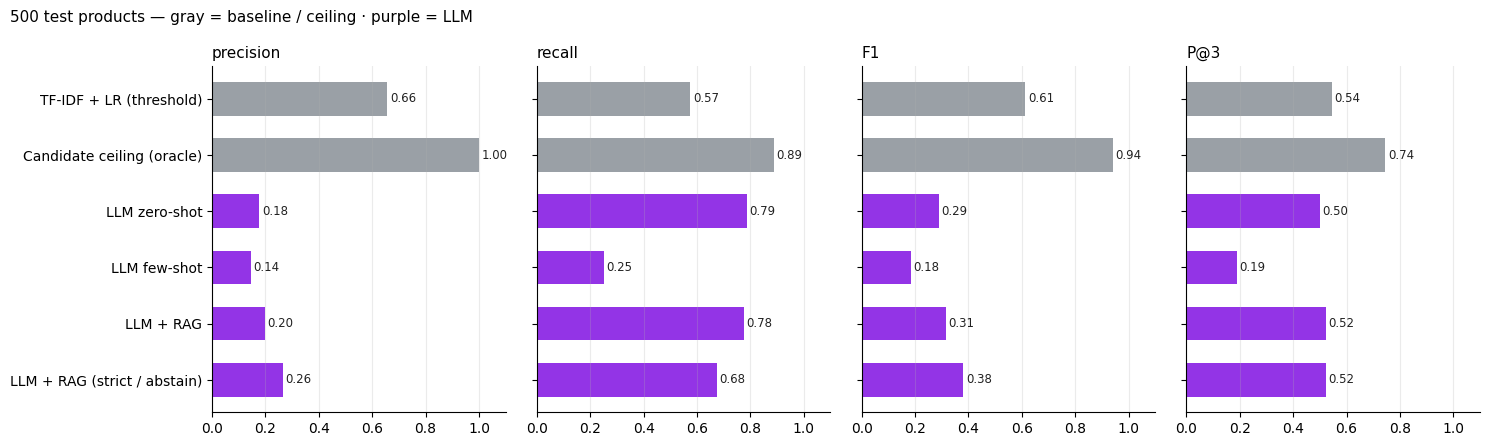

In [30]:
res = pd.DataFrame(board).T
display(res.round(3))

show = ["precision", "recall", "F1", "P@3"]
colors = [GRAY if ("LR" in n or "ceiling" in n) else PURPLE for n in res.index]
fig, axes = plt.subplots(1, len(show), figsize=(15, 0.55 * len(res) + 1.2), sharey=True)
for ax, m in zip(axes, show):
    bars = ax.barh(res.index, res[m].astype(float), color=colors, height=0.6)
    for b_, v in zip(bars, res[m].astype(float)):
        ax.text(v + 0.01, b_.get_y() + b_.get_height() / 2, f"{v:.2f}", va="center", fontsize=8.5, color=INK)
    ax.set_title(m, loc="left", fontsize=11); ax.set_xlim(0, 1.1)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.25)
axes[0].invert_yaxis()
fig.suptitle("500 test products — gray = baseline / ceiling · purple = LLM", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

## 11 · Error analysis: what does the LLM do differently?
**Goal:** see *where* world knowledge helps (and where the LLM fails).
1. **Implicit tags:** of the true tags **not written** in the text, how many does each method choose? (Phases 2–4 were stuck here.)
2. **Examples:** products where the LLM and LR disagree — ✅ = true tag · ❌ = not a true tag (remember: some ❌ are **missing labels**).

In [31]:
def contains(value, text):
    return re.search(r"(?<!\w)" + re.escape(value) + r"(?!\w)", text) is not None

TAG_VAL = np.array([t.split("=", 1)[1] for t in TAGS])
low = te_df.loc[EVAL, "clean"].str.lower().values
pairs = pd.DataFrame([(i, j, contains(TAG_VAL[j], low[i])) for i in range(N_EVAL) for j in np.flatnonzero(Y_ev[i])],
                     columns=["row", "tag", "explicit"])
sets = {"TF-IDF + LR": binarize(S_ev_lr, thr_lr), **{n: p["Pset"] for n, p in preds.items()}}
rows = []
for name, P in sets.items():
    hit = P[pairs["row"], pairs["tag"]].astype(bool)
    rows.append({"method": name, "explicit tags chosen": hit[pairs["explicit"]].mean(),
                 "implicit tags chosen": hit[~pairs["explicit"]].mean()})
print(f"True tags in the sample: {len(pairs):,} | explicit: {pairs['explicit'].mean():.0%}")
pd.DataFrame(rows).set_index("method").round(3)

True tags in the sample: 80 | explicit: 51%


,explicit tags chosen,implicit tags chosen
method,,
TF-IDF + LR,0.732,0.410
LLM zero-shot,0.878,0.692
LLM few-shot,0.268,0.231
LLM + RAG,0.854,0.692
LLM + RAG (strict / abstain),0.756,0.590


In [32]:
def compare(name, n=6, seed=0):
    P_llm, P_lr = preds[name]["Pset"], sets["TF-IDF + LR"]
    diff = [i for i in range(N_EVAL) if (P_llm[i] != P_lr[i]).any()]
    nice = lambda i, js: " | ".join(f"{'✅' if Y_ev[i, j] else '❌'} {NICE[j]}" for j in js) or "—"
    print(f"{name}: differs from LR on {len(diff)} / {N_EVAL} products\n")
    for i in np.random.default_rng(seed).choice(diff, min(n, len(diff)), replace=False):
        print(f"▶ {te_df.loc[EVAL[i], 'title_txt'][:100]}")
        print(f"   true: {', '.join(NICE[np.flatnonzero(Y_ev[i])])}")
        print(f"   LR  : {nice(i, np.flatnonzero(P_lr[i]))}")
        print(f"   LLM : {nice(i, np.flatnonzero(P_llm[i]))}")
        print(f"   raw : {preds[name]['answers'][i].strip()[:150]}\n")

best_llm = max(preds, key=lambda n: board[n]["F1"]) if preds else None
if best_llm: compare(best_llm)

LLM + RAG (strict / abstain): differs from LR on 30 / 30 products

▶ Elite99 Gelpolish Soak-off Gel Nail Polish UV LED Nail Art Set of 5 8ml C008
   true: Finish Type: glossy, Item Form: gel, Material Feature: non-toxic
   LR  : ✅ Finish Type: glossy | ✅ Item Form: gel
   LLM : ❌ Color: green | ✅ Finish Type: glossy | ✅ Item Form: gel | ❌ Material Feature: cruelty free | ✅ Material Feature: non-toxic
   raw : {"tags": ["Finish Type: glossy", "Material Feature: non-toxic", "Material Feature: cruelty free", "Item Form: gel", "Color: green"]}

▶ Jaciya Handmade Pearl Hair Clips Hairpins Hair Barrettes Big Hair Clips Headwear Hair Accessories fo
   true: Hair Type: curly, Hair Type: straight, Hair Type: wavy, Material: pearl
   LR  : ❌ Material: metal | ✅ Material: pearl
   LLM : ❌ Age Range (Description): child | ❌ Color: black | ❌ Color: blue | ❌ Color: gold | ❌ Color: silver | ❌ Color: white | ✅ Hair Type: curly | ✅ Hair Type: straight | ✅ Hair Type: wavy | ❌ Material: acrylic | ❌ Mater

**How to read it:**
- **Implicit tags chosen:** the key number for the proposal. If an LLM row is clearly above TF-IDF + LR, **world knowledge adds information the text doesn't contain** — the first method to do so.
- **Examples:** look at the **raw** answer too — is it clean JSON? Does the LLM pick tags that are ❌ but actually **correct** (missing labels)? Does it make **world-knowledge** mistakes?

## 12 · Save for Phase 6 (the agent)
The agent will reuse: the **prompt builders**, the **parser**, the **LoRA adapter** and the **evaluation sample**.

In [33]:
TAG = f"cpu_{N_EVAL}"          # marks these as the CPU learning run

np.save(f"{OUT}/eval_rows_in_test_{TAG}.npy", EVAL)
json.dump({n: {k: (None if v is None else round(float(v), 4)) for k, v in r.items()} for n, r in board.items()},
          open(f"{OUT}/results_{TAG}.json", "w"), indent=2)
pd.DataFrame({n: p["answers"] for n, p in preds.items()}).to_csv(f"{OUT}/llm_raw_answers_{TAG}.csv", index=False)
print("Saved:", sorted(os.listdir(OUT)))

# ft.save_pretrained(f"{OUT}/lora_qwen2.5-1.5b")   # skipped: no LoRA on CPU
# print("LoRA adapter saved")

Saved: ['eval_rows_in_test_cpu_30.npy', 'llm_raw_answers_cpu_30.csv', 'results_cpu_30.json']


## 13 · Phase 5 summary

> ⚠️ **This run = learning run, not thesis evidence.** Qwen2.5-**0.5B** on **CPU**, **30** test products, no LoRA.
> Numbers are noisy (each product ≈ 3% of the score). Final results: Qwen2.5-1.5B on GPU, 500 products (table at the bottom).

### 🎯 The goal of Phase 5
Phases 2–4 (text, retrieval, graph) all learn **only from our own data**, so P@3 got stuck at ~0.46. They cannot know that *"body wave bundles"* means *Hair Type: wavy* unless our data has taught them that.
An **LLM brings outside knowledge** (it has read the web). Question: **does that knowledge help it choose better tags?**

### 🧩 The pipeline (same for every approach)
1. **Candidates:** TF-IDF + LR gives the **top-15 tags** for each product. The LLM may only choose from these.
   → The best possible result = **candidate ceiling (oracle)**: recall 0.888, meaning 11% of the true tags are not in the top-15 and can never be found.
2. **Prompt:** product text + candidates + rules → the LLM answers in **JSON** `{"tags": [...]}`.
3. **Parser:** reads the JSON; if the answer is cut off, it still recovers the complete tags. Tags not in the candidate list are counted as **invalid** and dropped.
4. **Score:** precision, recall, F1, P@3 against the true tags, on the same products as LR.

### 📚 The approaches: what each one tests
**1. Zero-shot**: only the product + candidates + rules.
- *Tests:* can the LLM choose using its **own knowledge** alone?
- *CPU run:* it kept **11.8 of 15** candidates → recall high (0.79), precision very low (0.18). It **copied the list** instead of choosing.

**2. Few-shot**: + 3 worked examples from train products, where only *some* candidates are correct.
- *Tests:* can examples teach **how to do the task** (choose only a few, the right ones)?
- *CPU run:* avg tags fell to **4.6** (it learned the **format**), but F1 fell to 0.18 (it did not learn the **judgement**). It probably also copied tags from the examples (invalid ↑).

**3. RAG (Retrieval-Augmented Generation)**: + the **5 most similar train products** (MiniLM neighbours from Phase 3) and their tags.
- *Tests:* can the LLM **read the evidence and judge it**, instead of letting neighbours vote blindly like kNN?
- *Not the same as few-shot:* few-shot examples teach *the task*; RAG neighbours are **different for every product** and give *evidence about which tags fit*.
- *CPU run:* F1 0.32, about the same as zero-shot. The 0.5B model did not really use the evidence.

**4. RAG strict / abstain**: same as RAG + the rule *"choose a tag only if the text clearly supports it; otherwise return nothing."*
- *Tests:* the **precision–coverage trade-off** via the prompt (like raising a threshold).
- *CPU run:* avg tags 10.5 → 6.8, precision 0.20 → 0.27, recall 0.78 → 0.68 → **the trade-off works**. But empty % stayed 0: the small model **never said "I don't know"**.

**5. LoRA fine-tuning** *(skipped on CPU)*: prompting only *asks* the model; fine-tuning *teaches* it.
- How: freeze the LLM and train small add-on matrices (rank 16, ~0.5% of the parameters) on **2,000 train products** (prompt → true tags as JSON). The loss is only on the answer.
- *Tests:* does learning **our** tag names and labelling style beat general knowledge? Usually the biggest jump.

### 🏁 CPU learning-run results (0.5B, 30 products)
| Method | precision | recall | F1 | P@3 | avg tags | invalid | s / product |
|---|---|---|---|---|---|---|---|
| TF-IDF + LR | 0.657 | 0.575 | **0.613** | 0.544 | 2.3 | — | < 0.001 |
| Candidate ceiling | 1.000 | 0.888 | 0.940 | 0.744 | 2.4 | — | — |
| LLM zero-shot | 0.177 | 0.788 | 0.290 | 0.500 | 11.8 | 0.23 | 10.8 |
| LLM few-shot | 0.145 | 0.250 | 0.183 | 0.189 | 4.6 | 0.30 | 29.9 |
| LLM + RAG | 0.197 | 0.775 | 0.315 | 0.522 | 10.5 | 0.17 | 18.9 |
| LLM + RAG (strict) | 0.265 | 0.675 | 0.380 | 0.522 | 6.8 | 0.33 | 19.2 |

**Implicit tags** (true tags *not* written in the text; 49% of the 80 true tags): LR found 0.41, LLM zero-shot / RAG 0.69.
→ ⚠️ This is **not** proof of world knowledge: the LLM chose ~10 tags per product, so it found implicit tags **by chance**.

### 🔑 How to read LLM results (lessons that hold at any size)
1. **Always read recall together with avg tags.** High recall with ~10 tags (truth ≈ 2.4) just means it is guessing everything.
2. **P@3 can be borrowed.** Candidates come in LR's order. If the LLM copies that order, its P@3 is really LR's ranking.
3. **Some ❌ are actually right (missing labels).** E.g. *"Velvet Scrunchies"*: the LLM said *Material: velvet* and was marked ❌, because the vendor never tagged it, even though "velvet" is in the title. Measured precision **underestimates** models that spot real but untagged attributes → human check in Phase 7.
4. **Prompt wording acts like a soft threshold** (strict: precision ↑, recall ↓).
5. **Model size matters for selection.** 0.5B changes the *format* of its answer with the prompt, but not its *quality*.
6. **Cost:** 10–30 s per product on CPU vs < 0.001 s for LR → an LLM must earn its cost.

### 🖥️ Final run (fill in later): Qwen2.5-1.5B, GPU, 500 products
| Method | precision | recall | F1 | P@3 | avg tags | invalid | s / product |
|---|---|---|---|---|---|---|---|
| TF-IDF + LR | | | | | | — | |
| Candidate ceiling | | | | | | — | |
| LLM zero-shot | | | | | | | |
| LLM few-shot | | | | | | | |
| LLM + RAG | | | | | | | |
| LLM + RAG (strict) | | | | | | | |
| LLM + LoRA | | | | | | | |

Check first: avg tags close to ~2.4? Precision close to or above LR? Implicit gain **with** a normal avg tags?

### ➡️ Next: Phase 6 (the agent)
We now have **tools**: LR (candidates), retrieval (similar products), the tag graph (partners, conflicts) and an LLM (judgement + knowledge). The CPU run showed the LLM is **slow** and **can't abstain on its own** → the agent uses the cheap model first, calls the LLM **only when unsure**, and a **verifier** accepts, rejects or abstains for each tag.

*Saved: `results_cpu_30.json`, `llm_raw_answers_cpu_30.csv`, `eval_rows_in_test_cpu_30.npy`.*